In [2]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from collections import Counter
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Embedding, Conv1D, GlobalMaxPooling1D
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from sklearn.model_selection import train_test_split
from tensorflow.keras.layers import Dropout
from torch.utils.data import TensorDataset, DataLoader, random_split

In [3]:
df = pd.read_csv(r"C:\Users\hp\Downloads\UNI\Spring 2026\Bachelor\Bachelor_Project\data\combined_processed_v1.csv")

In [6]:
df.head()

,text,class
0,So if he hit her in the same way for what she ...,1
1,"oh fuck im late, , i missed stupid shit im sur...",0
2,"They get attitudes like bitches too , i think ...",1
3,Im mad james let me drink that shit... payback...,1
4,"Wait.. Who respects Colin..., #mkr",0


In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 48049 entries, 0 to 48048
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   text    48049 non-null  str  
 1   class   48049 non-null  int64
dtypes: int64(1), str(1)
memory usage: 750.9 KB


In [20]:
df.describe()

,class
count,48040.000000
mean,0.577873
std,0.493904
min,0.000000
25%,0.000000
50%,1.000000
75%,1.000000
max,1.000000


In [21]:
df.isnull().sum()

text          0
class         0
clean_text    0
dtype: int64

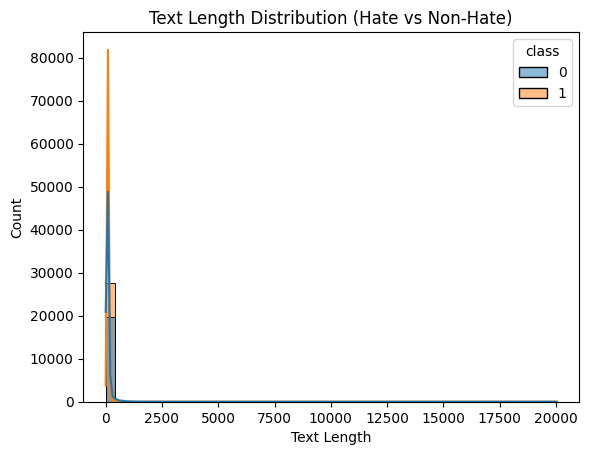

In [22]:
#text length distribution
df['text_length'] = df['text'].apply(len)

sns.histplot(data=df, x='text_length', hue='class', bins=50, kde=True)

plt.title("Text Length Distribution (Hate vs Non-Hate)")
plt.xlabel("Text Length")
plt.ylabel("Count")
plt.show()

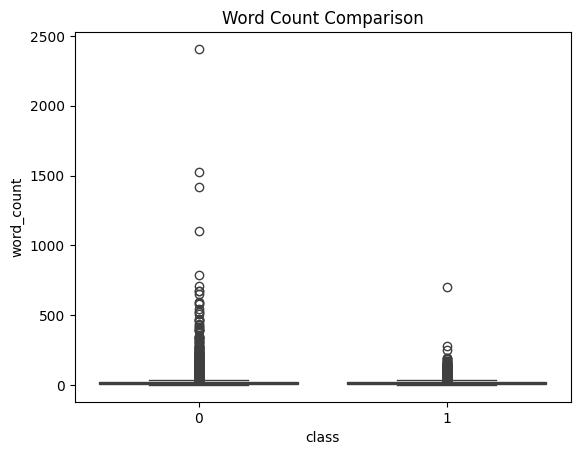

In [ ]:
#word count comparison
df['word_count'] = df['text'].apply(lambda x: len(x.split()))

sns.boxplot(x='class', y='word_count', data=df)
plt.title("Word Count Comparison")
plt.show()

In [12]:
#most frequent words
from collections import Counter

hate_text = " ".join(df[df['class']==1]['text'])
not_hate_text = " ".join(df[df['class']==0]['text'])

hate_words = Counter(hate_text.split()).most_common(20)
not_hate_words = Counter(not_hate_text.split()).most_common(20)

print("Top Hate Words:", hate_words)
print("Top Non-Hate Words:", not_hate_words)

Top Hate Words: [('a', 10786), ('the', 8388), ('I', 7757), ('you', 6987), ('to', 6822), ('bitch', 6713), ('RT', 6232), ('and', 4898), ('that', 4031), ('is', 3921), ('of', 3849), ('in', 3406), ('my', 3046), ('like', 2885), ('on', 2691), ('be', 2682), ('bitches', 2598), ('me', 2456), ('are', 2431), ('for', 2383)]
Top Non-Hate Words: [('the', 11940), ('to', 8770), ('a', 7494), ('and', 6509), ('of', 5821), ('I', 5553), ('is', 5037), ('you', 4661), ('in', 4256), ('that', 3863), ('are', 3178), ('for', 3125), ('on', 2490), ('it', 2347), ('have', 2187), ('be', 2184), ('not', 2146), ('#MKR', 1999), ('with', 1935), ('#mkr', 1814)]


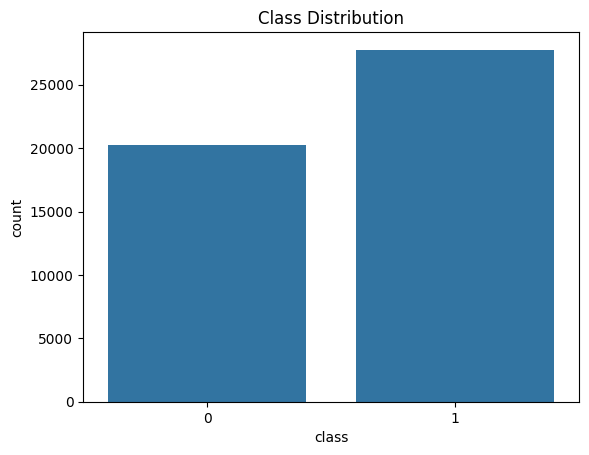

In [24]:
#class distribution
sns.countplot(x='class', data=df)
plt.title("Class Distribution")
plt.show()

In [25]:
#hate bigram analysis (2,2)
from sklearn.feature_extraction.text import CountVectorizer
hate_texts = df[df['class'] == 1]['text']
non_hate_texts = df[df['class'] == 0]['text']
vectorizer = CountVectorizer(
    ngram_range=(2,2),
    stop_words='english',
    max_features=20
)

X_hate = vectorizer.fit_transform(hate_texts)

bigrams = vectorizer.get_feature_names_out()
counts = X_hate.sum(axis=0).A1

bigram_df = pd.DataFrame({
    'bigram': bigrams,
    'count': counts
}).sort_values(by='count', ascending=False)

print("Top Hate Speech Bigrams:")
print(bigram_df)

Top Hate Speech Bigrams:
           bigram  count
2   128514 128514   1631
9       bitch ass    249
4   128557 128557    225
15     like bitch    224
17      look like    201
5       ass bitch    196
19       yo bitch    194
7       bad bitch    184
8     bad bitches    148
6       ass nigga    145
3   128514 128557    139
11     bitch http    139
13     fuck bitch    139
10      bitch don    134
12       don know    132
16   little bitch    130
14          gt gt    122
1   128175 128175    122
0     12288 12288    119
18    u2026 u2026    118


In [26]:
#non hate bigram analysis (2,2)
vectorizer = CountVectorizer(
    ngram_range=(2,2),
    stop_words='english',
    max_features=20
)

X_nonhate = vectorizer.fit_transform(non_hate_texts)

bigrams = vectorizer.get_feature_names_out()
counts = X_nonhate.sum(axis=0).A1

bigram_df_nonhate = pd.DataFrame({
    'bigram': bigrams,
    'count': counts
}).sort_values(by='count', ascending=False)

print("Top Non-Hate Bigrams:")
print(bigram_df_nonhate)

Top Non-Hate Bigrams:
           bigram  count
16        xa0 xa0   1969
18        xc2 xa0    547
10      kat andre    342
19        xe2 x80    277
13    mkr mkr2015    161
9         kat amp    133
2       amp andre    127
4        don know    115
12     looks like    103
0   128514 128514     89
11      look like     87
7       http 8230     86
5        don like     77
15         ve got     75
17        xa0 xc2     72
6       don think     72
8       http shar     68
14        shar es     68
3       andre mkr     64
1       9733 9733     64
